# E02 · 车道线检测 V2.0

## 00 · 环境与素材
Hough 候选线段不是人工 Ground Truth，候选数不能当作准确率。

In [1]:

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
def locate_images():
    here=Path.cwd().resolve()
    for root in [here,*here.parents]:
        p=root/'images'
        if (p/'01_solidWhiteRight_straight_white.jpg').exists(): return p
    kaggle=Path('/kaggle/input')
    if kaggle.exists():
        for p in kaggle.glob('**/images/01_solidWhiteRight_straight_white.jpg'): return p.parent
    raise FileNotFoundError('请解压完整教学包，确保 images/ 与 Notebook 一同提供')
IMAGES=locate_images()
def read(name):
    x=cv2.imread(str(IMAGES/name))
    if x is None: raise FileNotFoundError(name)
    return x
def view(items):
    fig,axs=plt.subplots(1,len(items),figsize=(5*len(items),4))
    if len(items)==1: axs=[axs]
    for ax,(name,img) in zip(axs,items):
        ax.imshow(img if img.ndim==2 else cv2.cvtColor(img,cv2.COLOR_BGR2RGB),cmap='gray' if img.ndim==2 else None)
        ax.set_title(name);ax.axis('off')
    plt.tight_layout();plt.show()
print('Image path:',IMAGES,'OpenCV:',cv2.__version__)


Image path: /home/runner/work/multimodal-document-ai-learning-center/multimodal-document-ai-learning-center/docs/resources/course-labs/intelligent-perception/images OpenCV: 5.1.0


## 01 · 探索实验一：Canny 阈值
边缘越多越好吗？

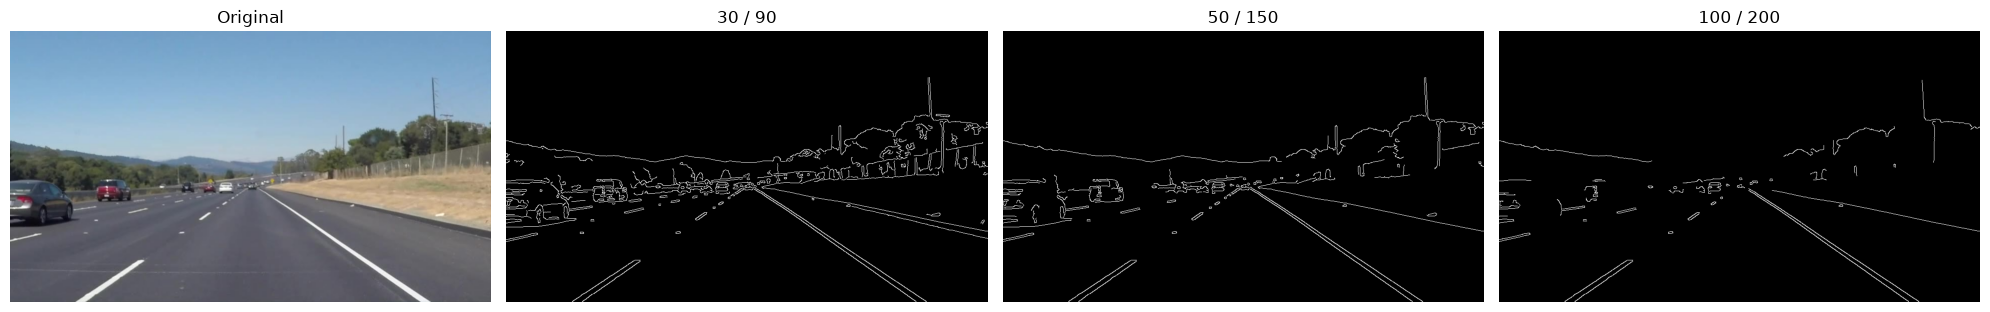

In [2]:
img=read('01_solidWhiteRight_straight_white.jpg')
blur=cv2.GaussianBlur(cv2.cvtColor(img,cv2.COLOR_BGR2GRAY),(5,5),1.2)
view([('Original',img),('30 / 90',cv2.Canny(blur,30,90)),
('50 / 150',cv2.Canny(blur,50,150)),('100 / 200',cv2.Canny(blur,100,200))])


### 探索任务 1 · Canny 参数实验 Cell
先预测：低阈值是不是越低越好？
1. 只改变阈值，比较道路内外边缘。
2. 观察标线断裂与车辆边缘。
3. 判断为何不能用边缘总数评价准确率。

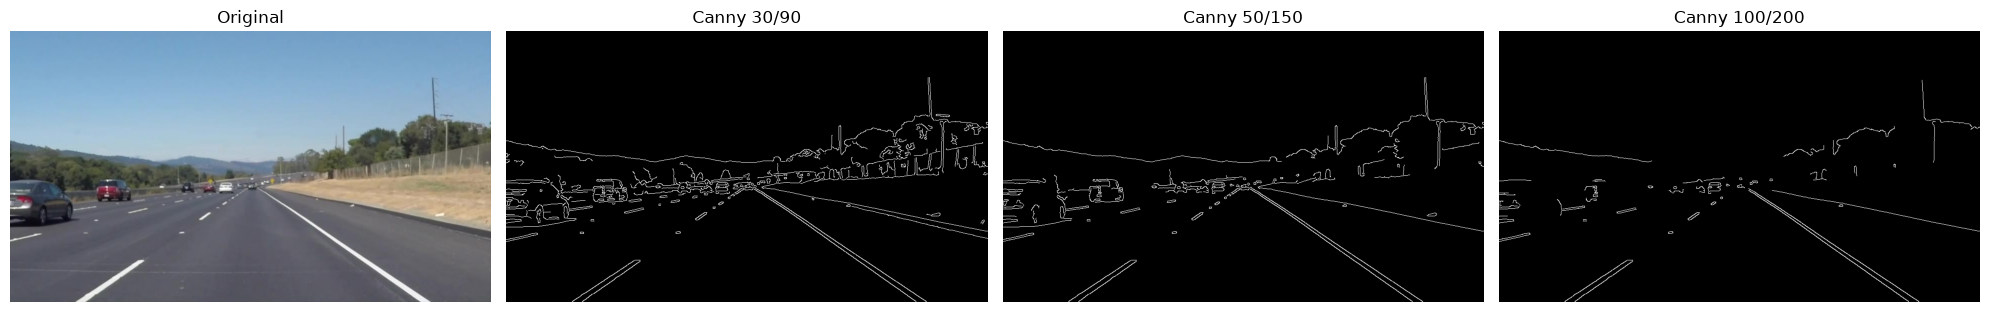

In [3]:
img=read('01_solidWhiteRight_straight_white.jpg')
g=cv2.GaussianBlur(cv2.cvtColor(img,cv2.COLOR_BGR2GRAY),(5,5),1.2)
view([('Original',img)]+[(f'Canny {lo}/{hi}',cv2.Canny(g,lo,hi)) for lo,hi in ((30,90),(50,150),(100,200))])

## 02 · 探索实验二：ROI 感兴趣区域
修改 ROI 梯形顶部比例与 Hough 参数。

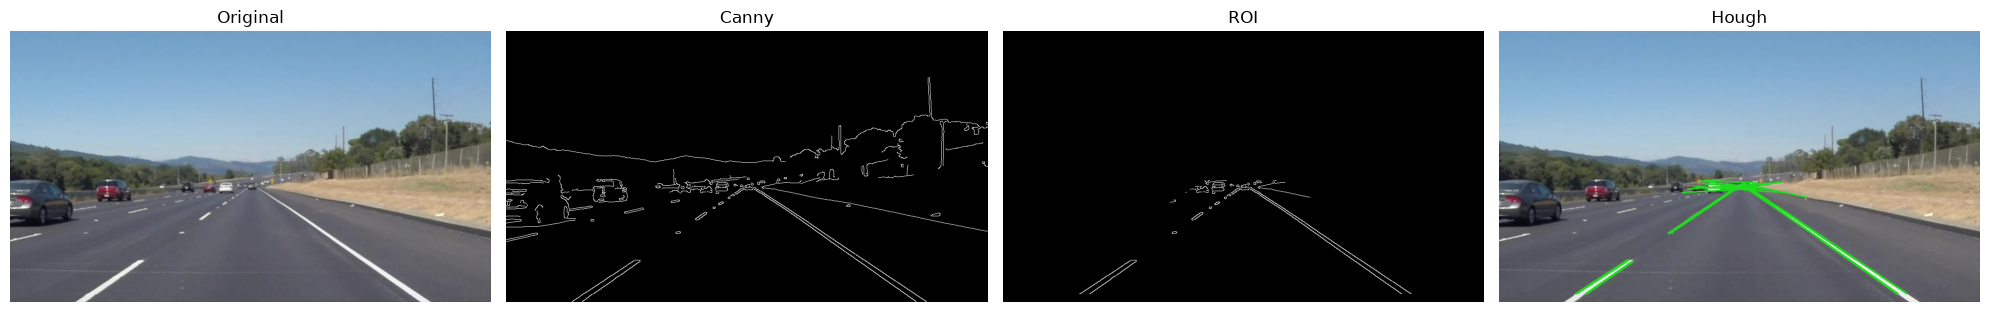

Hough candidates: 24


In [4]:
def pipeline(img,top=.55,lo=50,hi=150,votes=25,length=35,gap=70):
    h,w=img.shape[:2]
    gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    edges=cv2.Canny(cv2.GaussianBlur(gray,(5,5),1.2),lo,hi)
    mask=np.zeros((h,w),np.uint8)
    poly=np.array([[(int(.05*w),int(.97*h)),(int(.42*w),int(top*h)),
                    (int(.58*w),int(top*h)),(int(.98*w),int(.97*h))]],np.int32)
    cv2.fillPoly(mask,poly,255)
    roi=cv2.bitwise_and(edges,mask)
    result=img.copy()
    lines=cv2.HoughLinesP(roi,1,np.pi/180,threshold=votes,minLineLength=length,maxLineGap=gap)
    found=[] if lines is None else np.asarray(lines).reshape(-1,4).tolist()
    for x1,y1,x2,y2 in found:
        cv2.line(result,(x1,y1),(x2,y2),(30,220,30),2)
    return edges,roi,result,found
img=read('01_solidWhiteRight_straight_white.jpg')
edge,roi,overlay,lines=pipeline(img)
view([('Original',img),('Canny',edge),('ROI',roi),('Hough',overlay)])
print('Hough candidates:',len(lines))


### 探索任务 2 · ROI 感兴趣区域实验 Cell
先预测：ROI 变小会不会删除真正的远处标线？
1. 比较顶部比例 0.45、0.55、0.65。
2. 在弯道场景重复参数比较。
3. 解释固定 ROI 的视角限制。

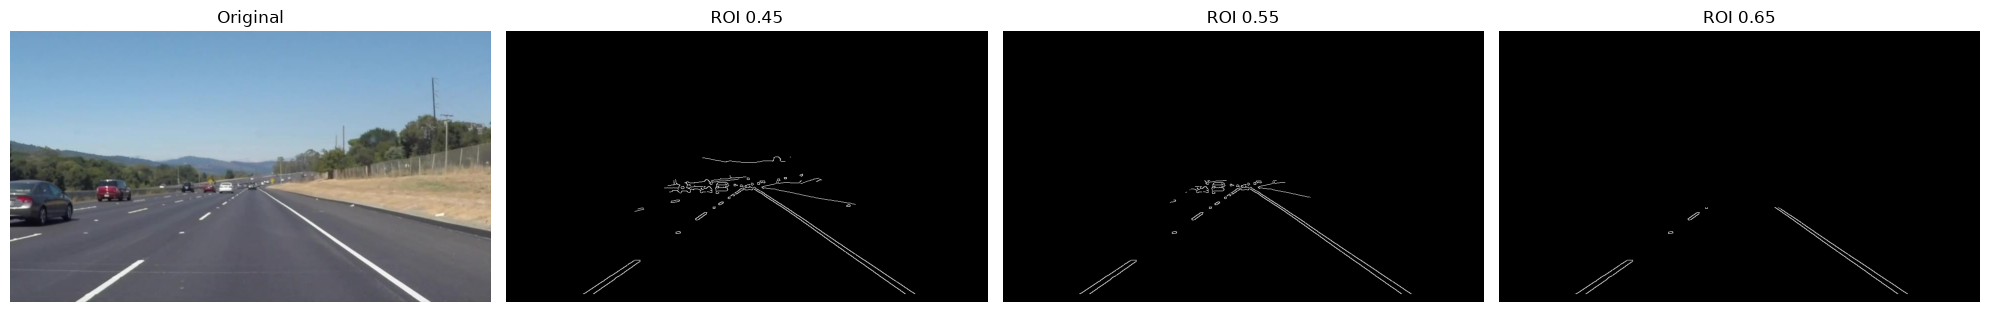

In [5]:
img=read('01_solidWhiteRight_straight_white.jpg')
panels=[('Original',img)]
for top in (.45,.55,.65):
    _,roi,_,_=pipeline(img,top=top)
    panels.append((f'ROI {top}',roi))
view(panels)

## 03 · 探索实验三：Hough 变换
先预测：线段候选数量越多，检测结果是否更好？

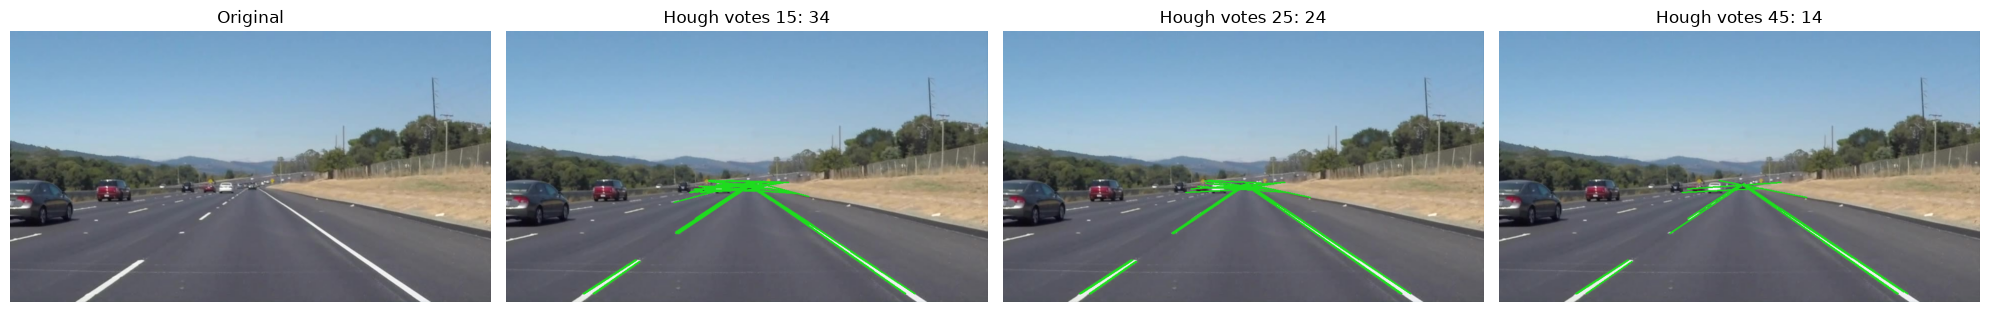

In [6]:
img=read('01_solidWhiteRight_straight_white.jpg')
panels=[('Original',img)]
for votes in (15,25,45):
    _,_,overlay,lines=pipeline(img,votes=votes)
    panels.append((f'Hough votes {votes}: {len(lines)}',overlay))
view(panels)

### 探索任务 3 · Hough 参数实验 Cell
1. 比较投票阈值 15、25、45。
2. 再修改最小线段长度和最大间隙。
3. 找一个非车道线的候选，并解释原因。

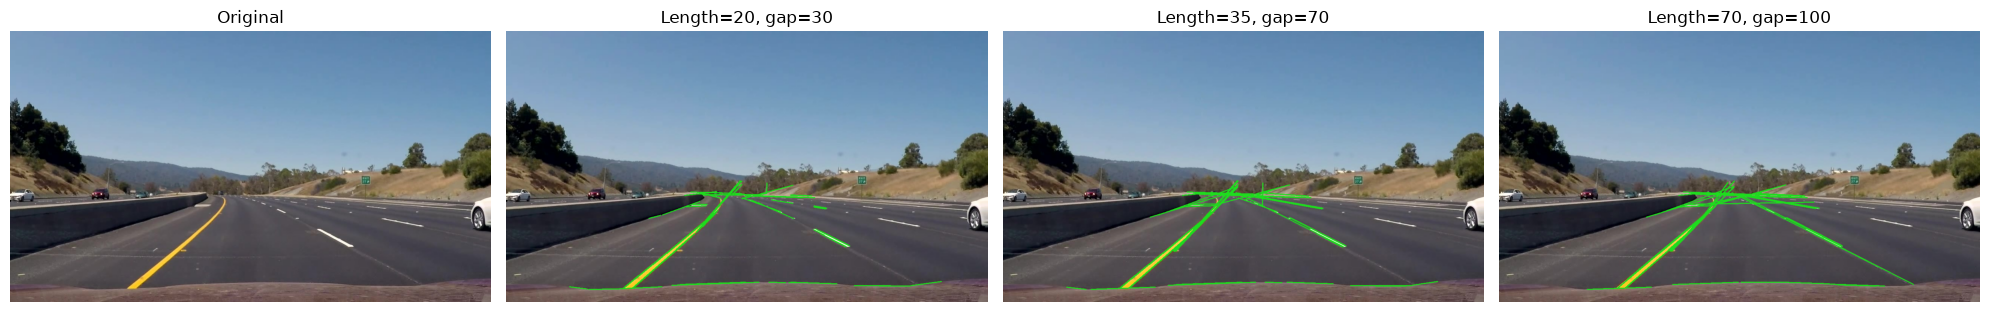

In [7]:
img=read('03_project_curve_intro.jpg')
panels=[('Original',img)]
for length,gap in ((20,30),(35,70),(70,100)):
    _,_,overlay,_=pipeline(img,length=length,gap=gap)
    panels.append((f'Length={length}, gap={gap}',overlay))
view(panels)

## 04 · 探索实验四：左右候选线筛选
根据斜率区分左右候选线，但没有语义识别能力。

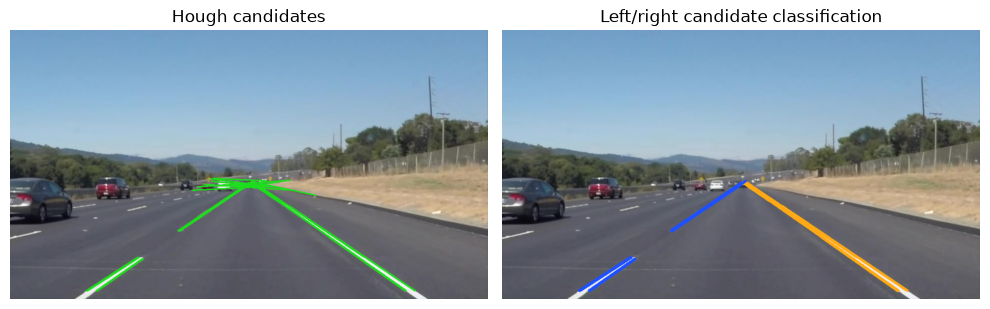

In [8]:
img=read('01_solidWhiteRight_straight_white.jpg')
_,_,all_lines,lines=pipeline(img)
h,w=img.shape[:2]
left_right=img.copy()
for x1,y1,x2,y2 in lines:
    if abs(y2-y1)<5: continue
    slope=(x2-x1)/(y2-y1)
    if abs(slope)<.45: continue
    xb=x1+slope*(.97*h-y1)
    if slope<0 and .03*w<xb<.5*w: color=(255,80,30)
    elif slope>0 and .5*w<xb<.97*w: color=(20,170,255)
    else: continue
    cv2.line(left_right,(x1,y1),(x2,y2),color,4)
view([('Hough candidates',all_lines),('Left/right candidate classification',left_right)])


### 探索任务 4 · 左右线段筛选实验 Cell
先预测：车辆干扰时，几何筛选是否可靠？
1. 比较直道和车辆干扰场景。
2. 记录错误候选与缺失边界。
3. 解释几何证据与真实道路标注的区别。

Straight candidate segments: 24


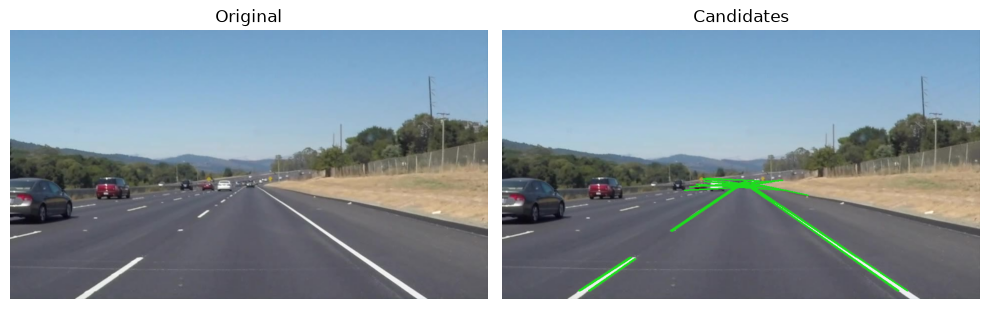

Traffic candidate segments: 36


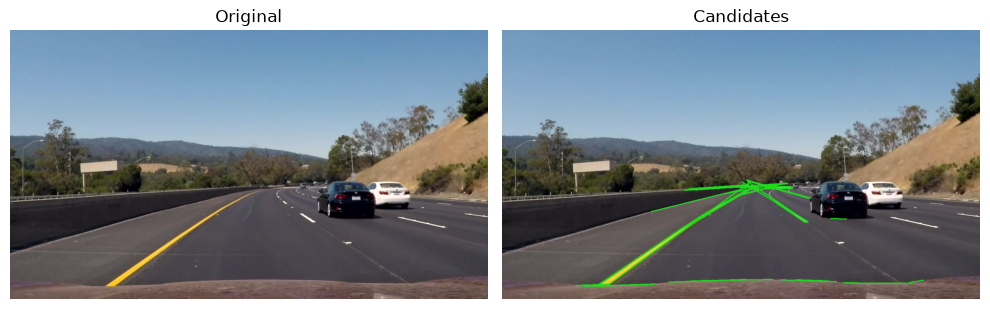

In [9]:
for title,name in [('Straight','01_solidWhiteRight_straight_white.jpg'),('Traffic','04_project_curve_traffic.jpg')]:
    img=read(name)
    _,_,overlay,lines=pipeline(img)
    print(title,'candidate segments:',len(lines))
    view([('Original',img),('Candidates',overlay)])

## 05 · 探索实验五：固定参数九图泛化
不针对每张图片单独调参，寻找误检和漏检的原因。

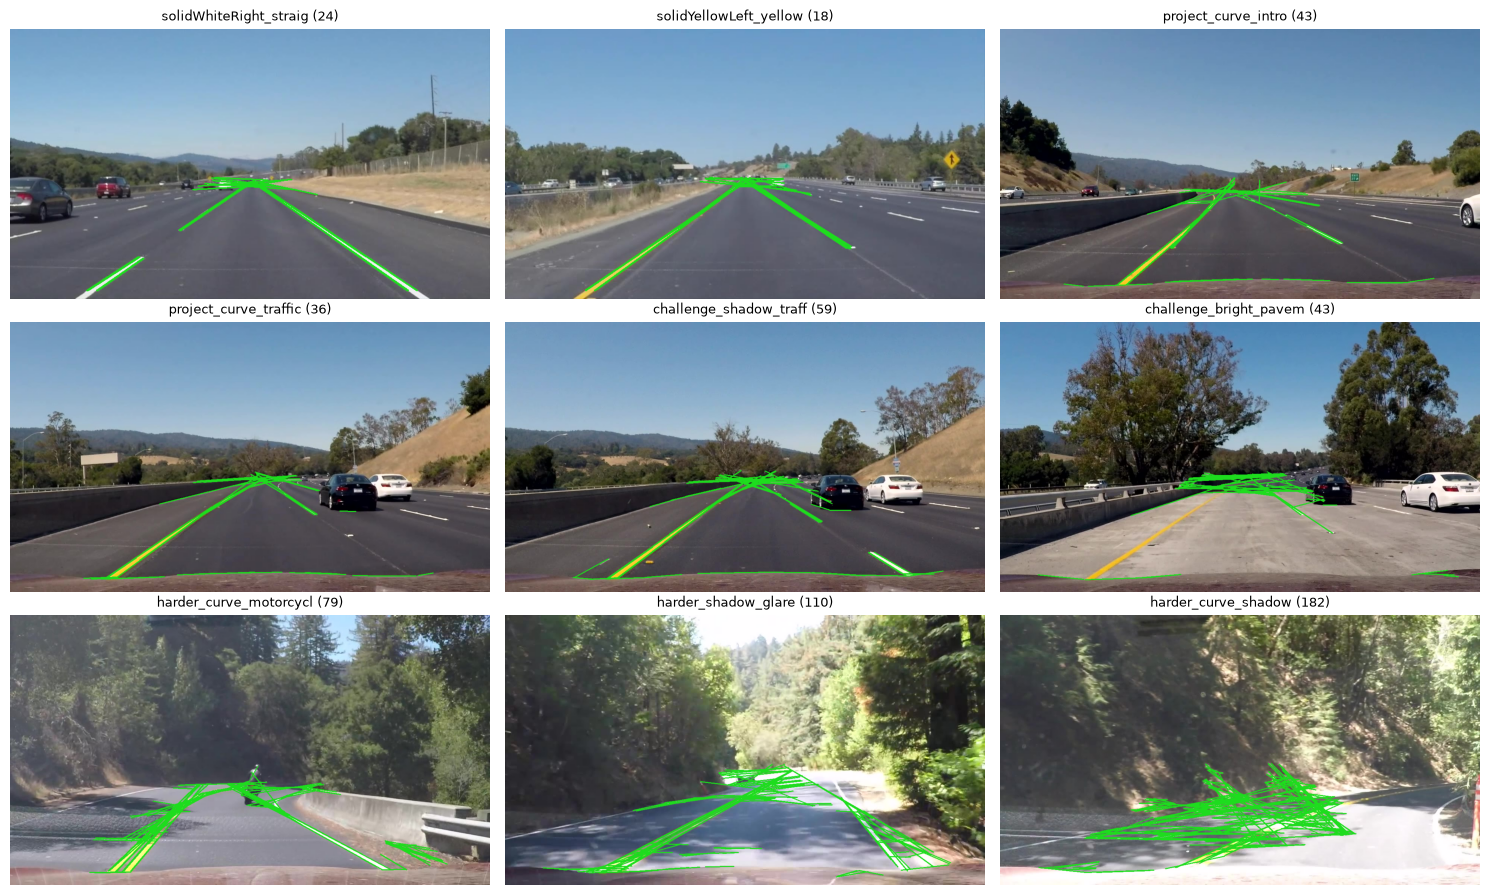

In [10]:
files=sorted(IMAGES.glob('*.jpg'))
fig,ax=plt.subplots(3,3,figsize=(15,9))
for a,p in zip(ax.flat,files):
    _,_,result,lines=pipeline(read(p.name))
    a.imshow(cv2.cvtColor(result,cv2.COLOR_BGR2RGB))
    a.set_title(p.stem[3:25]+f' ({len(lines)})',fontsize=9);a.axis('off')
plt.tight_layout();plt.show()


### 探索任务 5 · 九图参数泛化实验 Cell
先预测：固定参数能否同时适应直道、弯道和阴影？
1. 不改参数，找出两种失败场景。
2. 只修改 ROI 位置，观察一处改善、一处变差。
3. 讨论光照、曲率、遮挡对传统检测的影响。

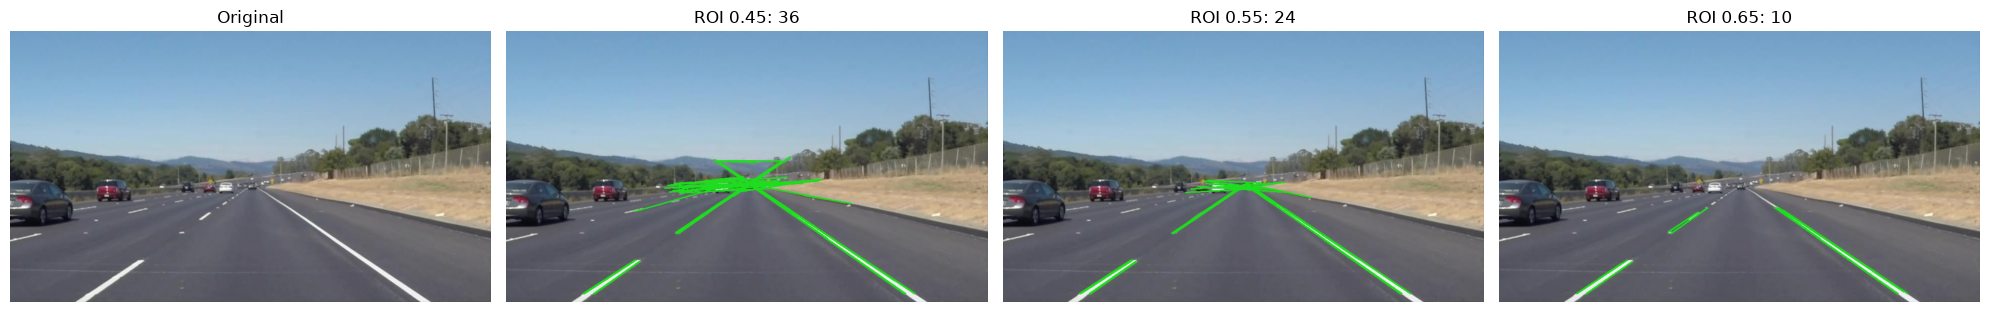

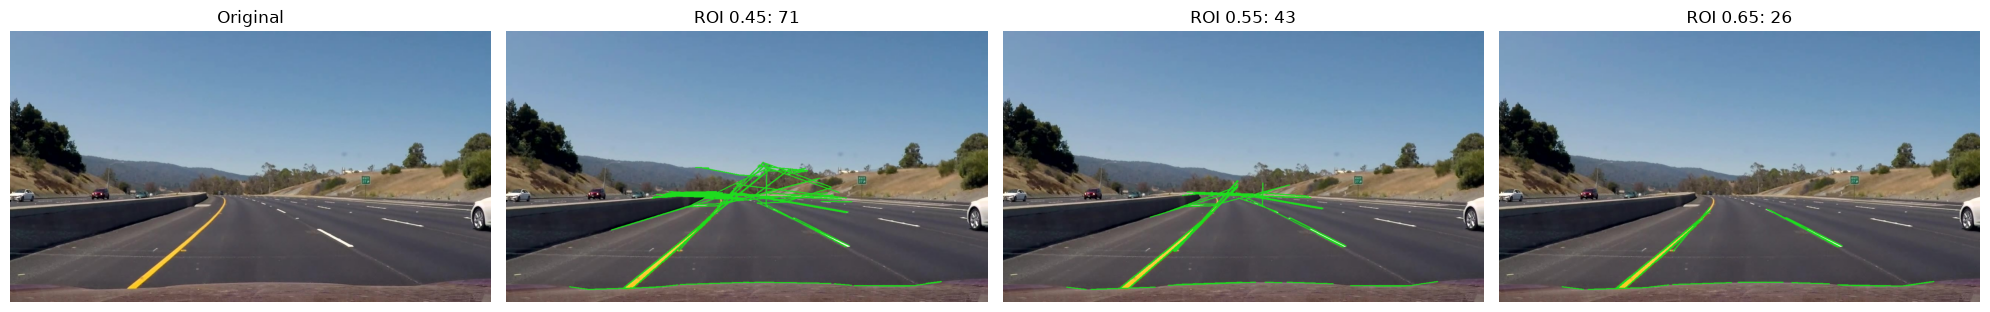

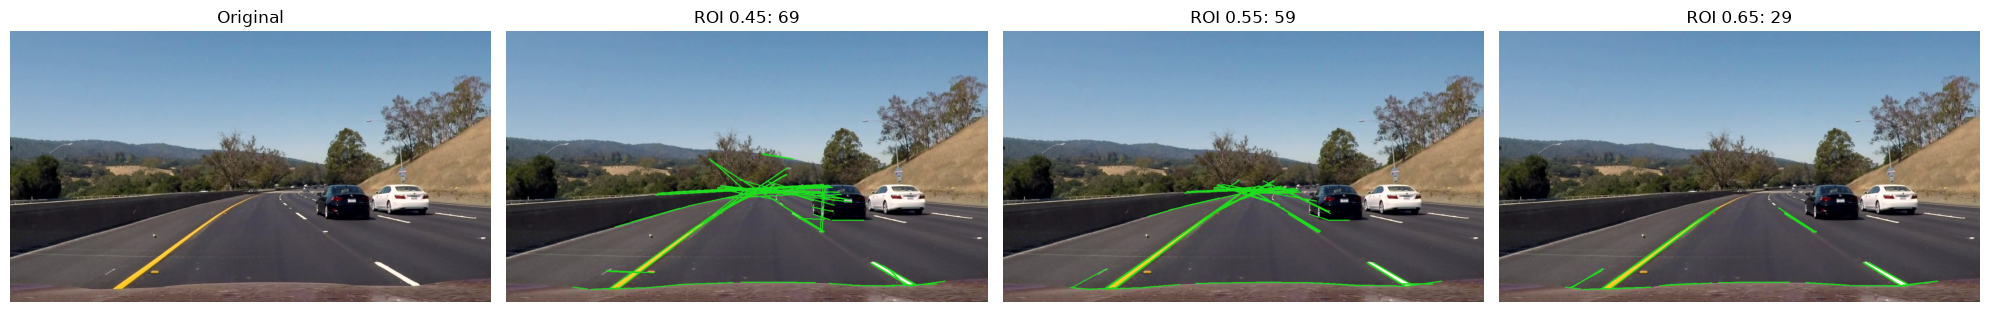

In [11]:
for name in ('01_solidWhiteRight_straight_white.jpg','03_project_curve_intro.jpg','05_challenge_shadow_traffic.jpg'):
    img=read(name)
    panels=[('Original',img)]
    for top in (.45,.55,.65):
        _,_,overlay,lines=pipeline(img,top=top)
        panels.append((f'ROI {top}: {len(lines)}',overlay))
    view(panels)

## 06 · 连续视频（拓展）
将相同的 Canny、ROI、Hough 参数应用于整段视频，观察候选线变化与抖动。本方法不包含时序跟踪。
**探索：** 哪些时间点的检测突然变化？可以怎样减少跨帧抖动？

逐帧处理 200 帧，时长 8.0 秒，视频文件：E02_lane_video_cv2.mp4


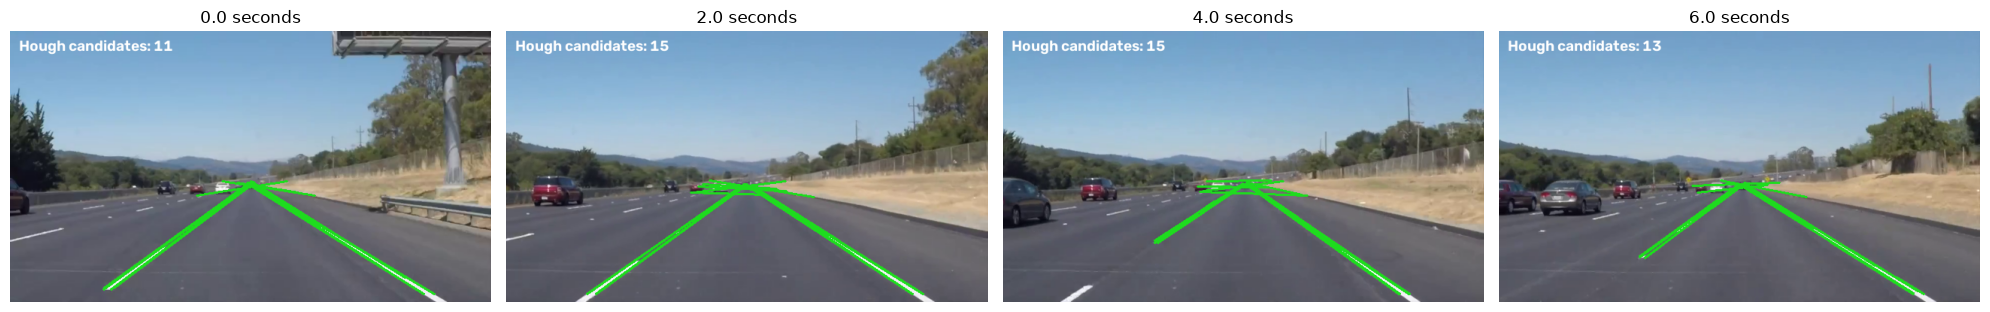

In [12]:

from pathlib import Path
def find_video():
    options=[IMAGES.parent/"videos"/"solidWhiteRight_8s.mp4",
             IMAGES.parent/"downloads"/"solidWhiteRight_8s.mp4",
             Path.cwd()/"videos"/"solidWhiteRight_8s.mp4"]
    for p in options:
        if p.is_file(): return p
    kaggle=Path("/kaggle/input")
    if kaggle.exists():
        for p in kaggle.glob("**/solidWhiteRight_8s.mp4"): return p
    raise FileNotFoundError("未找到 E02 的 8 秒视频：请使用完整实验包")
cap=cv2.VideoCapture(str(find_video()))
if not cap.isOpened(): raise RuntimeError("无法读取教学视频")
fps=cap.get(cv2.CAP_PROP_FPS)
fps=fps if fps>1 else 25.0
path=Path.cwd()/"E02_lane_video_cv2.mp4"
w,h=640,360
out=cv2.VideoWriter(str(path),cv2.VideoWriter_fourcc(*"mp4v"),fps,(2*w,h))
if not out.isOpened():
    cap.release()
    raise RuntimeError("OpenCV 当前环境不支持 mp4v 编码")
examples=[]
count=0
while True:
    ok,frame=cap.read()
    if not ok:break
    original=cv2.resize(frame,(w,h))
    _,_,overlay,lines=pipeline(original)
    cv2.putText(overlay,f"Hough candidates: {len(lines)}",(12,26),
                cv2.FONT_HERSHEY_SIMPLEX,.65,(255,255,255),2)
    out.write(np.hstack((original,overlay)))
    if count%max(1,round(fps*2))==0 and len(examples)<4:
        examples.append((f"{count/fps:.1f} seconds",overlay.copy()))
    count+=1
cap.release()
out.release()
if count<2 or not path.is_file() or path.stat().st_size<10000:
    raise RuntimeError("没有生成有效的连续视频结果")
print(f"逐帧处理 {count} 帧，时长 {count/fps:.1f} 秒，视频文件：{path.name}")
view(examples)


## 总结与进一步探索
1. 哪种参数变化产生了你未预期的输出？
2. 哪些结论只在当前素材成立？
3. 选择一个失败案例并说明可能的算法改进方向。